# Exploración inicial MiBici: ¿qué traen los datos y qué cambió con las bicis eléctricas?

**Objetivo:** antes de definir el problema de ML, revisar con pocos archivos:

1. Qué columnas trae cada mes y si el formato cambió.
2. Qué problemas de calidad hay (nulos, duplicados, duraciones imposibles).
3. Qué estaciones aparecieron o desaparecieron.
4. Si la llegada de las bicis eléctricas (10 de junio de 2026) cambió el uso del sistema.

**Archivos:** mayo y julio de 2025 (para comparar contra el mismo mes del año anterior), mayo 2026 (último mes completo antes del cambio), junio 2026 (transición), julio 2026 (primer mes completo después) y septiembre 2026 (lo más reciente), más el catálogo de estaciones.

**Requisito:** haber descargado los datos con `make data` (o `python -m proyecto_mlops_equipo_9.download`) desde la raíz del repo. Este notebook no descarga nada; solo lee `data/raw`.

> Notebook exploratorio. La lógica de carga y limpieza que se defina aquí se pasa después a `dataset.py` y `cleaning.py`.
> Generado con ayuda de Claude (Anthropic); declararlo en la entrega.

## 0. Configuración

In [2]:
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd

# Las rutas vienen de config.py del proyecto, así el notebook funciona sin importar desde dónde se abra.
from proyecto_mlops_equipo_9.config import RAW_DATA_DIR

VIAJES_DIR = RAW_DATA_DIR / "viajes"
ruta_estaciones = RAW_DATA_DIR / "estaciones" / "nomenclatura_2026_09.csv"

MESES = ["2025_05", "2025_07", "2026_05", "2026_06", "2026_07", "2026_09"]
archivos = {mes: VIAJES_DIR / f"datos_abiertos_{mes}.csv" for mes in MESES}

faltantes = [ruta for ruta in [*archivos.values(), ruta_estaciones] if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(
        "Faltan archivos en data/raw. Desde la raíz del repo corre: make data\n"
        + "\n".join(f"  {ruta}" for ruta in faltantes)
    )

INICIO_EBIKES = pd.Timestamp("2026-06-10")
MES_REFERENCIA = "2026_05"  # último mes completo antes de las e-bikes

for mes, ruta in archivos.items():
    print(f"{mes}: {ruta.stat().st_size / 1e6:.1f} MB")

2025_05: 34.3 MB
2025_07: 31.9 MB
2026_05: 27.4 MB
2026_06: 30.8 MB
2026_07: 33.7 MB
2026_09: 42.6 MB


## 1. ¿Cambió el formato? Encabezados de cada archivo

Se leen solo 5 filas de cada mes para comparar columnas sin cargar todo. Si algún mes trae una columna nueva (por ejemplo, tipo de bici), aparece aquí.

In [3]:
def leer_muestra(ruta, filas=5):
    """Lee unas filas probando utf-8 y, si falla, latin-1. Regresa (muestra, encoding)."""
    try:
        return pd.read_csv(ruta, nrows=filas, encoding="utf-8"), "utf-8"
    except UnicodeDecodeError:
        return pd.read_csv(ruta, nrows=filas, encoding="latin-1"), "latin-1"


encabezados = {}
for mes, ruta in archivos.items():
    muestra, encoding = leer_muestra(ruta)
    encabezados[mes] = {"encoding": encoding, "columnas": list(muestra.columns)}
    print(f"{mes} ({encoding}): {list(muestra.columns)}")

referencia = set(encabezados[MES_REFERENCIA]["columnas"])
print()
for mes, info in encabezados.items():
    columnas = set(info["columnas"])
    if columnas == referencia:
        print(f"{mes}: mismas columnas que {MES_REFERENCIA}")
    else:
        print(f"AVISO {mes}: nuevas={columnas - referencia}  faltan={referencia - columnas}")

2025_05 (utf-8): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
2025_07 (latin-1): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
2026_05 (utf-8): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
2026_06 (utf-8): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
2026_07 (utf-8): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
2026_09 (utf-8): ['Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']

2025_05: mismas columnas que 2026_05
2025_07: mismas columnas que 2026_05
2026_05: mismas columnas que 2026_05
2026_06: mismas columnas que 2026_05
2026_07: mismas

## 2. Carga completa con nombres de columna estándar

Los nombres originales traen acentos y mayúsculas (`Año_de_nacimiento`). Se convierten a nombres simples para que el código funcione aunque algún año los escriba distinto. Una columna desconocida se conserva con su nombre, para que la vean.

`NULL` (sin comillas) aparece en el CSV como valor vacío; se trata como nulo.

In [4]:
PREFIJOS = {
    "viaje": "viaje_id", "usuario": "usuario_id", "genero": "genero",
    "inicio": "inicio", "fin": "fin", "origen": "origen_id", "destino": "destino_id",
}


def nombre_estandar(columna):
    limpio = unicodedata.normalize("NFKD", columna).encode("ascii", "ignore").decode()
    limpio = re.sub(r"\W+", "_", limpio.strip().lower()).strip("_")
    if "nacimiento" in limpio:
        return "anio_nacimiento"
    for prefijo, nombre in PREFIJOS.items():
        if limpio.startswith(prefijo):
            return nombre
    return limpio


def a_fecha(serie):
    fechas = pd.to_datetime(serie, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    if fechas.isna().mean() > 0.5:  # otro formato de fecha (posible en años anteriores)
        fechas = pd.to_datetime(serie, errors="coerce", dayfirst=True)
    return fechas


def cargar_mes(ruta, encoding):
    df = pd.read_csv(ruta, encoding=encoding, na_values=["NULL", ""], low_memory=False)
    df = df.rename(columns=nombre_estandar)
    df["inicio"] = a_fecha(df["inicio"])
    df["fin"] = a_fecha(df["fin"])
    df["duracion_min"] = (df["fin"] - df["inicio"]).dt.total_seconds() / 60
    return df


viajes = {}
for mes, ruta in archivos.items():
    viajes[mes] = cargar_mes(ruta, encabezados[mes]["encoding"])
    memoria = viajes[mes].memory_usage(deep=True).sum() / 1e6
    print(f"{mes}: {len(viajes[mes]):,} viajes ({memoria:.0f} MB en memoria)")

viajes[MES_REFERENCIA].head()

2025_05: 395,891 viajes (45 MB en memoria)
2025_07: 368,186 viajes (42 MB en memoria)
2026_05: 315,895 viajes (36 MB en memoria)
2026_06: 355,303 viajes (40 MB en memoria)
2026_07: 388,257 viajes (44 MB en memoria)
2026_09: 490,056 viajes (56 MB en memoria)


,viaje_id,usuario_id,genero,anio_nacimiento,inicio,fin,origen_id,destino_id,duracion_min
0,43984118,1012132,M,2000.0,2026-05-01 00:01:04,2026-05-01 00:09:41,51,281,8.616667
1,43984121,3460331,F,1999.0,2026-05-01 00:01:19,2026-05-01 00:16:13,51,379,14.900000
2,43984122,171205,M,1987.0,2026-05-01 00:01:21,2026-05-01 00:28:46,341,359,27.416667
3,43984125,33523,M,1992.0,2026-05-01 00:01:59,2026-05-01 00:11:02,26,397,9.050000
4,43984127,4045170,M,1998.0,2026-05-01 00:03:04,2026-05-01 00:19:10,268,257,16.100000


In [5]:
viajes[MES_REFERENCIA].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315895 entries, 0 to 315894
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   viaje_id         315895 non-null  int64         
 1   usuario_id       315895 non-null  int64         
 2   genero           314191 non-null  object        
 3   anio_nacimiento  315887 non-null  float64       
 4   inicio           315895 non-null  datetime64[ns]
 5   fin              315895 non-null  datetime64[ns]
 6   origen_id        315895 non-null  int64         
 7   destino_id       315895 non-null  int64         
 8   duracion_min     315895 non-null  float64       
dtypes: datetime64[ns](2), float64(2), int64(4), object(1)
memory usage: 21.7+ MB


## 3. Calidad de datos

Cada conteo es un candidato a regla de limpieza. Se anotan cuántos casos hay y se decidira qué hacer con cada uno (eliminar, corregir o conservar), justificación va en el reporte.

In [6]:
def resumen_calidad(df):
    edad = df["inicio"].dt.year - df["anio_nacimiento"]
    return {
        "viajes": len(df),
        "viaje_id_duplicado": int(df["viaje_id"].duplicated().sum()),
        "fila_duplicada": int(df.duplicated().sum()),
        "genero_nulo": int(df["genero"].isna().sum()),
        "anio_nac_nulo": int(df["anio_nacimiento"].isna().sum()),
        "fecha_invalida": int(df["inicio"].isna().sum() + df["fin"].isna().sum()),
        "duracion_negativa": int((df["duracion_min"] < 0).sum()),
        "duracion_menor_1min": int(df["duracion_min"].between(0, 1, inclusive="left").sum()),
        "duracion_mayor_3h": int((df["duracion_min"] > 180).sum()),
        "mismo_origen_destino": int((df["origen_id"] == df["destino_id"]).sum()),
        "edad_menor_15": int((edad < 15).sum()),
        "edad_mayor_90": int((edad > 90).sum()),
    }


calidad = pd.DataFrame({mes: resumen_calidad(df) for mes, df in viajes.items()}).T
calidad

,viajes,viaje_id_duplicado,fila_duplicada,genero_nulo,anio_nac_nulo,fecha_invalida,duracion_negativa,duracion_menor_1min,duracion_mayor_3h,mismo_origen_destino,edad_menor_15,edad_mayor_90
2025_05,395891,0,0,3706,96,0,0,10051,32,22287,66,10
2025_07,368186,0,0,3464,38,0,0,9773,35,21363,64,0
2026_05,315895,0,0,1704,8,0,0,10777,37,22407,0,23
2026_06,355303,0,0,2283,10,0,0,17725,68,28896,0,26
2026_07,388257,0,0,2651,61,0,0,16627,59,29653,0,18
2026_09,490056,758,758,3295,9,0,0,18966,37,33812,0,8


In [7]:
# Lo mismo en porcentaje del total de viajes de cada mes
calidad_pct = calidad.drop(columns="viajes").div(calidad["viajes"], axis=0) * 100
calidad_pct.round(2)

,viaje_id_duplicado,fila_duplicada,genero_nulo,anio_nac_nulo,fecha_invalida,duracion_negativa,duracion_menor_1min,duracion_mayor_3h,mismo_origen_destino,edad_menor_15,edad_mayor_90
2025_05,0.00,0.00,0.94,0.02,0.0,0.0,2.54,0.01,5.63,0.02,0.00
2025_07,0.00,0.00,0.94,0.01,0.0,0.0,2.65,0.01,5.80,0.02,0.00
2026_05,0.00,0.00,0.54,0.00,0.0,0.0,3.41,0.01,7.09,0.00,0.01
2026_06,0.00,0.00,0.64,0.00,0.0,0.0,4.99,0.02,8.13,0.00,0.01
2026_07,0.00,0.00,0.68,0.02,0.0,0.0,4.28,0.02,7.64,0.00,0.00
2026_09,0.15,0.15,0.67,0.00,0.0,0.0,3.87,0.01,6.90,0.00,0.00


In [8]:
# Valores que aparecen en la columna de género, por mes
pd.DataFrame({mes: df["genero"].value_counts(dropna=False) for mes, df in viajes.items()})

,2025_05,2025_07,2026_05,2026_06,2026_07,2026_09
genero,,,,,,
M,281885,263661,227901,258048,280680,352032
F,110300,101061,86290,94972,104926,134729
NaN,3706,3464,1704,2283,2651,3295


### Viajes "imposibles": pocos segundos entre estaciones distintas

Hay viajes de unos segundos que "terminan" en una estación distinta a la de salida. Físicamente no es posible; probablemente son artefactos del sistema (ajustes, mantenimiento o pruebas). Esta celda cuenta cuántos hay por mes y a qué estaciones llegan; la sección 6 muestra en qué días se concentran.

In [22]:
for mes, df in viajes.items():
    raros = df[(df["duracion_min"] * 60 <= 5) & (df["origen_id"] != df["destino_id"])]
    destinos = raros["destino_id"].value_counts().head(3).to_dict()
    print(f"{mes}: {len(raros):,} viajes de 5s o menos entre estaciones distintas; destinos más comunes: {destinos}")

2025_05: 452 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {51: 49, 260: 13, 108: 13}
2025_07: 488 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {54: 15, 206: 15, 303: 12}
2026_05: 536 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {271: 18, 35: 17, 397: 15}
2026_06: 3,356 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {51: 99, 257: 57, 38: 56}
2026_07: 1,581 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {194: 42, 51: 32, 50: 32}
2026_09: 1,134 viajes de 5s o menos entre estaciones distintas; destinos más comunes: {70: 22, 56: 22, 257: 20}


## 4. Estaciones: catálogo y estaciones nuevas

El catálogo de septiembre de 2026 trae `dpcapacity` (capacidad de anclajes). Las estaciones dadas de baja tienen el prefijo `ex-` en el nombre y algunas tienen capacidad 0. Algunos códigos (como `GDL-020`) se reutilizaron, así que la llave correcta es `id`, no el código del nombre.

In [23]:
estaciones = pd.read_csv(ruta_estaciones, encoding=leer_muestra(ruta_estaciones)[1])
estaciones.columns = [c.strip().lower() for c in estaciones.columns]
estaciones["dada_de_baja"] = estaciones["name"].str.startswith("ex-")

print(estaciones.columns.tolist())
print(f"{len(estaciones)} estaciones en el catálogo; {estaciones['dada_de_baja'].sum()} con prefijo 'ex-'")
estaciones.describe()

['id', 'name', 'latitude', 'longitude', 'dpcapacity', 'dada_de_baja']
484 estaciones en el catálogo; 14 con prefijo 'ex-'


,id,latitude,longitude,dpcapacity
count,484.000000,484.000000,484.000000,484.000000
mean,254.758264,20.678520,-103.361871,16.882231
std,148.293765,0.022032,0.031626,4.126942
min,2.000000,20.636130,-103.433215,0.000000
25%,129.750000,20.665077,-103.384164,15.000000
50%,252.000000,20.674390,-103.362443,15.000000
75%,379.250000,20.688609,-103.339320,19.000000
max,519.000000,20.739523,-103.297112,39.000000


In [ ]:
usadas = {
    mes: set(df["origen_id"].dropna().astype(int)) | set(df["destino_id"].dropna().astype(int))
    for mes, df in viajes.items()
}
ids_catalogo = set(estaciones["id"])
antes = usadas[MES_REFERENCIA]

resumen_estaciones = pd.DataFrame([
    {
        "mes": mes,
        "estaciones_usadas": len(ids),
        "id_maximo": max(ids),
        f"nuevas_vs_{MES_REFERENCIA}": len(ids - antes),
        f"sin_uso_vs_{MES_REFERENCIA}": len(antes - ids),
        "sin_catalogo": len(ids - ids_catalogo),
    }
    for mes, ids in usadas.items()
]).set_index("mes")

display(resumen_estaciones)

,estaciones_usadas,id_maximo,nuevas_vs_2026_05,sin_uso_vs_2026_05,sin_catalogo
mes,,,,,
2025_05,367,398,11,15,0
2025_07,367,400,10,14,0
2026_05,371,419,0,0,0
2026_06,427,503,57,1,2
2026_07,453,510,83,1,1
2026_09,468,519,98,1,0


In [ ]:
# Estaciones que aparecen a partir de junio de 2026 y no existían en mayo de 2026
meses_despues = [mes for mes in viajes if mes >= "2026_06"]
nuevas = sorted(set().union(*(usadas[mes] for mes in meses_despues)) - antes)
print(f"{len(nuevas)} estaciones nuevas")

display(estaciones[estaciones["id"].isin(nuevas)][["id", "name", "dpcapacity"]])

100 estaciones nuevas


,id,name,dpcapacity
26,29,(GDL-027) C. Belén / C. San Felipe,15
47,50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,23
49,52,(GDL-050) C.Pedro Moreno /Federalismo,23
51,54,(GDL-052) Av. Juarez /16 de Septiembre,23
55,58,(GDL-056) Av. 16 de Sept. / C. Miguel Blanco,19
...,...,...,...
479,515,(GDL-295) C. Tarahumaras / Av. Manuel Acuña,15
480,516,(ZPN-105) Av. Atemajac/Colinas del Congreso,19
481,517,(ZPN-106) Av. Atemajac/Colinas del Capitolio,19
482,518,(ZPN-108) Av. Atemajac / Av. Yermo y Parra,19


## 5. ¿Qué cambió con las bicis eléctricas?

Ninguno de los seis meses trae una columna de tipo de bici, así que el efecto se busca de forma indirecta.

**Cuidado estacionalidad:** en Guadalajara la temporada de lluvias empieza en junio, así que comparar mayo contra julio mezcla el efecto de la lluvia con el de las e-bikes. Por eso se compara cada mes contra el **mismo mes del año anterior**. Si mayo 2025 → mayo 2026 creció un X% y julio 2025 → julio 2026 creció bastante más, la diferencia es una señal del cambio.

In [13]:
def resumen_mes(df):
    validos = df[df["duracion_min"].between(1, 180)]
    dias = df["inicio"].dt.normalize().nunique()
    return pd.Series({
        "viajes": len(df),
        "viajes_por_dia": len(df) / dias,
        "usuarios_unicos": df["usuario_id"].nunique(),
        "viajes_por_usuario": len(df) / df["usuario_id"].nunique(),
        "duracion_mediana_min": validos["duracion_min"].median(),
        "estaciones_usadas": pd.concat([df["origen_id"], df["destino_id"]]).nunique(),
        "pct_viajes_desde_estaciones_nuevas": df["origen_id"].isin(nuevas).mean() * 100,
    })


comparacion = pd.DataFrame({mes: resumen_mes(df) for mes, df in viajes.items()}).T
comparacion.round(2)

,viajes,viajes_por_dia,usuarios_unicos,viajes_por_usuario,duracion_mediana_min,estaciones_usadas,pct_viajes_desde_estaciones_nuevas
2025_05,395891.0,12770.68,16953.0,23.35,9.72,367.0,7.36
2025_07,368186.0,11876.97,16327.0,22.55,9.88,367.0,7.26
2026_05,315895.0,10190.16,15742.0,20.07,9.80,371.0,0.00
2026_06,355303.0,11843.43,16749.0,21.21,9.93,427.0,7.03
2026_07,388257.0,12524.42,16960.0,22.89,9.37,453.0,10.77
2026_09,490056.0,16335.20,17395.0,28.17,8.68,468.0,12.84


In [14]:
# Cambio porcentual contra el mismo mes del año anterior
for antes_mes, despues_mes in [("2025_05", "2026_05"), ("2025_07", "2026_07")]:
    cambio = (comparacion.loc[despues_mes] / comparacion.loc[antes_mes] - 1) * 100
    print(f"\n{antes_mes} -> {despues_mes} (cambio %)")
    print(cambio.drop("pct_viajes_desde_estaciones_nuevas").round(1).to_string())


2025_05 -> 2026_05 (cambio %)
viajes                 -20.2
viajes_por_dia         -20.2
usuarios_unicos         -7.1
viajes_por_usuario     -14.1
duracion_mediana_min     0.9
estaciones_usadas        1.1

2025_07 -> 2026_07 (cambio %)
viajes                   5.5
viajes_por_dia           5.5
usuarios_unicos          3.9
viajes_por_usuario       1.5
duracion_mediana_min    -5.2
estaciones_usadas       23.4


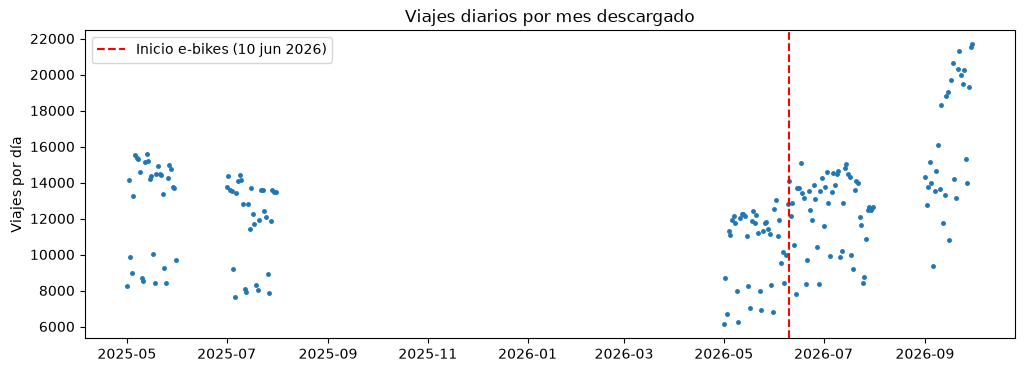

In [15]:
# Viajes por día en todos los meses descargados
columnas = ["inicio", "duracion_min", "origen_id"]
todos = pd.concat([df[columnas].assign(mes=mes) for mes, df in viajes.items()], ignore_index=True)
diarios = todos.groupby(todos["inicio"].dt.floor("D")).size()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(diarios.index, diarios.values, ".", markersize=5)
ax.axvline(INICIO_EBIKES, color="red", linestyle="--", label="Inicio e-bikes (10 jun 2026)")
ax.set_ylabel("Viajes por día")
ax.set_title("Viajes diarios por mes descargado")
ax.legend()
plt.show()

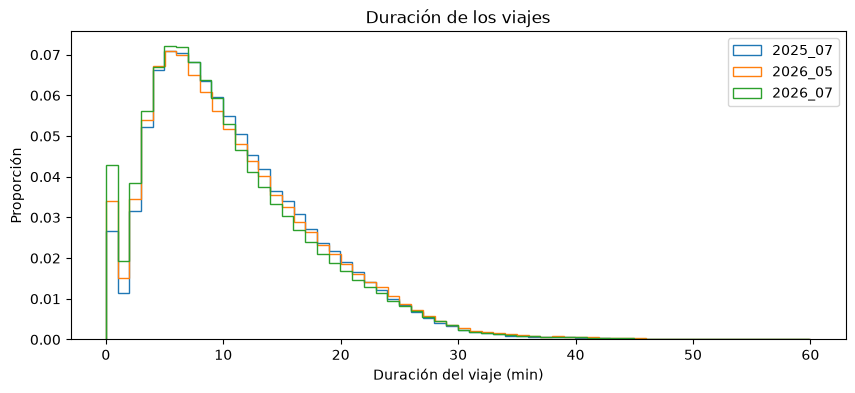

In [16]:
# Distribución de la duración: antes vs después, y contra el mismo mes de 2025
fig, ax = plt.subplots(figsize=(10, 4))
for mes in ["2025_07", "2026_05", "2026_07"]:
    duracion = viajes[mes]["duracion_min"]
    ax.hist(duracion[duracion.between(0, 60)], bins=60, density=True, histtype="step", label=mes)
ax.set_xlabel("Duración del viaje (min)")
ax.set_ylabel("Proporción")
ax.set_title("Duración de los viajes")
ax.legend()
plt.show()

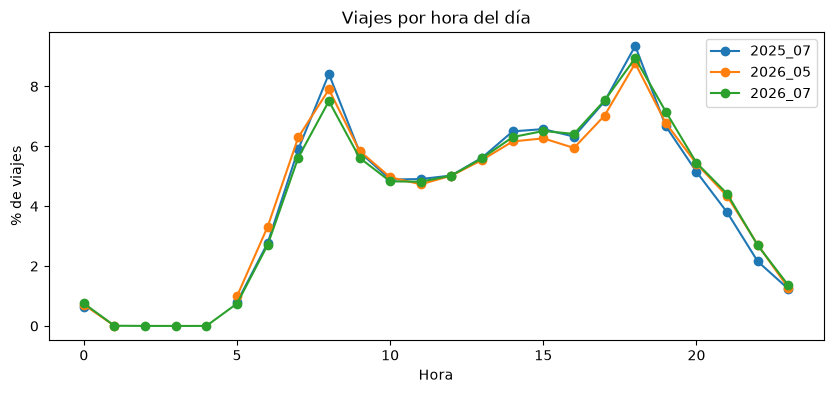

In [17]:
# Perfil horario: % de viajes de cada mes que inician en cada hora
perfil = pd.DataFrame({
    mes: viajes[mes]["inicio"].dt.hour.value_counts(normalize=True).sort_index() * 100
    for mes in ["2025_07", "2026_05", "2026_07"]
})
perfil.plot(figsize=(10, 4), marker="o", title="Viajes por hora del día", ylabel="% de viajes", xlabel="Hora")
plt.show()

In [18]:
# Después del cambio: ¿los viajes que salen de estaciones nuevas se comportan distinto?
julio = viajes["2026_07"].copy()
julio["estacion_nueva"] = julio["origen_id"].isin(nuevas)
validos = julio[julio["duracion_min"].between(1, 180)]
validos.groupby("estacion_nueva")["duracion_min"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
estacion_nueva,,,,,,,,
False,332791.0,11.0,7.4,1.0,5.8,9.3,14.6,177.0
True,38780.0,11.6,8.0,1.0,6.1,9.8,15.4,173.9


## 6. Tres preguntas abiertas: mayo, junio y septiembre de 2026

### 6.1 ¿La caída de mayo 2026 (−20% contra mayo 2025) fue de unos días o de todo el mes?

Se compara cada semana de mayo 2026 contra la misma semana de 2025, y cuántos viajes se perdieron en estaciones que dejaron de usarse.

In [19]:
semanas = pd.DataFrame({
    mes: viajes[mes].groupby((viajes[mes]["inicio"].dt.day - 1) // 7 + 1).size()
    for mes in ["2025_05", "2026_05"]
})
semanas.index.name = "semana_del_mes"
# La semana 5 son solo los días 29 a 31, así que su cambio depende de qué días de la semana caen ahí.
semanas["cambio_pct"] = (semanas["2026_05"] / semanas["2025_05"] - 1) * 100
print(semanas.round(1).to_string())

por_estacion = pd.DataFrame({
    mes: viajes[mes]["origen_id"].value_counts() for mes in ["2025_05", "2026_05"]
}).fillna(0)
perdidos_total = por_estacion["2025_05"].sum() - por_estacion["2026_05"].sum()
perdidos_cerradas = por_estacion.loc[por_estacion["2026_05"] == 0, "2025_05"].sum()
print(f"\nViajes perdidos: {perdidos_total:,.0f}; de ellos en estaciones sin uso en mayo 2026: {perdidos_cerradas:,.0f}")
for mes in ["2025_05", "2026_05"]:
    df = viajes[mes]
    print(f"{mes}: {len(df) / df['usuario_id'].nunique():.1f} viajes por usuario activo")

                2025_05  2026_05  cambio_pct
semana_del_mes                              
1                 85400    67949       -20.4
2                 93070    74627       -19.8
3                 90905    74615       -17.9
4                 89420    72406       -19.0
5                 37096    26298       -29.1

Viajes perdidos: 79,996; de ellos en estaciones sin uso en mayo 2026: 29,239
2025_05: 23.4 viajes por usuario activo
2026_05: 20.1 viajes por usuario activo


### 6.2 ¿En qué días de junio se concentran los viajes imposibles?

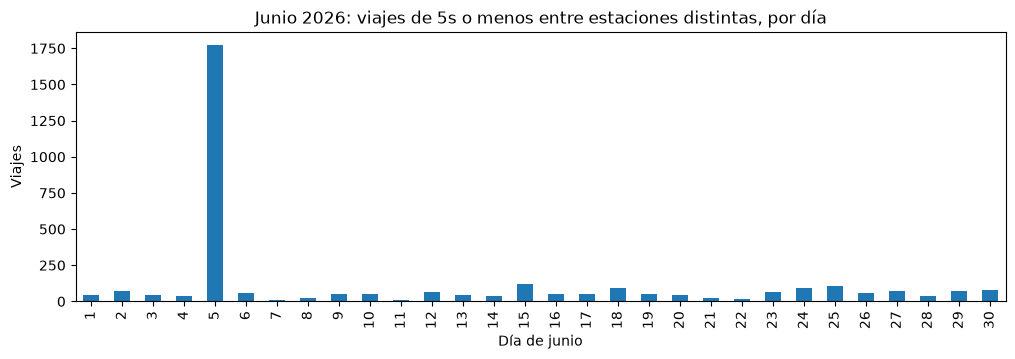

Día con más casos: 5 de junio (1,775 viajes); mediana diaria: 51


In [25]:
junio = viajes["2026_06"]
imposibles = junio[(junio["duracion_min"] * 60 <= 5) & (junio["origen_id"] != junio["destino_id"])]
por_dia = imposibles.groupby(imposibles["inicio"].dt.day).size()

ax = por_dia.plot(kind="bar", figsize=(12, 3.5), title="Junio 2026: viajes de 5s o menos entre estaciones distintas, por día")
ax.set_xlabel("Día de junio")
ax.set_ylabel("Viajes")
plt.show()
print(f"Día con más casos: {por_dia.idxmax()} de junio ({por_dia.max():,} viajes); mediana diaria: {por_dia.median():.0f}")

### 6.3 ¿El salto de septiembre 2026 viene de más usuarios o de más viajes por usuario?

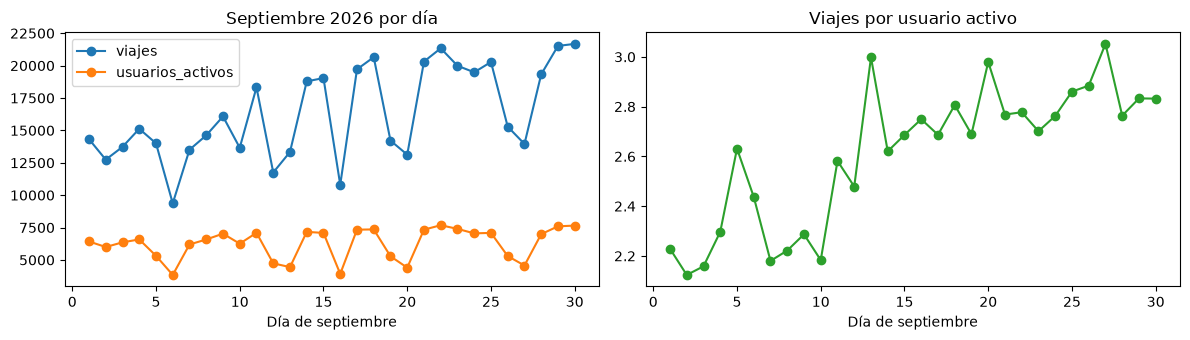

Días con más filas duplicadas: {30: 104, 22: 104, 15: 96, 25: 90, 18: 88}
Usuarios de septiembre que no aparecían de mayo a julio: 3,309 (69,257 viajes)


In [21]:
septiembre = viajes["2026_09"]
dia = septiembre["inicio"].dt.day
por_dia_sep = pd.DataFrame({
    "viajes": septiembre.groupby(dia).size(),
    "usuarios_activos": septiembre.groupby(dia)["usuario_id"].nunique(),
})
por_dia_sep["viajes_por_usuario"] = por_dia_sep["viajes"] / por_dia_sep["usuarios_activos"]

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
por_dia_sep[["viajes", "usuarios_activos"]].plot(ax=ejes[0], marker="o", title="Septiembre 2026 por día")
por_dia_sep["viajes_por_usuario"].plot(ax=ejes[1], marker="o", color="tab:green", title="Viajes por usuario activo")
for eje in ejes:
    eje.set_xlabel("Día de septiembre")
plt.tight_layout()
plt.show()

duplicados = septiembre[septiembre.duplicated(keep=False)]
print("Días con más filas duplicadas:", duplicados["inicio"].dt.day.value_counts().head(5).to_dict())

anteriores = set().union(*(set(viajes[m]["usuario_id"]) for m in ["2026_05", "2026_06", "2026_07"]))
nuevos = ~septiembre["usuario_id"].isin(anteriores)
print(f"Usuarios de septiembre que no aparecían de mayo a julio: {septiembre.loc[nuevos, 'usuario_id'].nunique():,} "
      f"({nuevos.sum():,} viajes)")

## 7. Hallazgos y siguientes pasos

Resultados con los datos de ene 2025 – sep 2026 descargados el 21 de octubre de 2026:

- **Formato:** los seis meses tienen las mismas 8 columnas y ninguna indica el tipo de bici. Julio 2025 viene en latin-1; los demás, en utf-8.
- **Calidad:** menos de 1% de género nulo; 2.5–5% de viajes de menos de 1 minuto; 758 filas duplicadas exactas, solo en septiembre 2026.
- **Estaciones:** de 371 estaciones usadas en mayo 2026 a 468 en septiembre. Unas 100 no tienen historial antes de junio, lo que favorece predecir por zona y no por estación.
- **Mayo 2026:** −20% contra mayo 2025, parejo todas las semanas. Más de un tercio de la caída viene de estaciones que dejaron de usarse (reubicaciones previas al lanzamiento).
- **Junio 2026:** el 5 de junio concentra la mayoría de los viajes imposibles del mes, cinco días antes del lanzamiento; se trata como día atípico.
- **Julio 2026:** +5.5% contra julio 2025; la duración mediana baja (9.9 → 9.4 min) y el perfil horario casi no cambia.
- **Septiembre 2026:** la segunda quincena sube a ~20,000 viajes por día con casi los mismos usuarios activos (2.2 → 2.8 viajes por usuario al día). La causa no está confirmada: puede ser comportamiento (viajes más cortos y encadenados) o un cambio en el registro.

**Decisiones propuestas para el pipeline:** entrenar con ene 2025 – mar 2026, validar con abr–may 2026 y usar jun–sep 2026 como escenario de *data drift* para la Fase 3. Las reglas de limpieza candidatas pasan al notebook 1.1 y luego a `cleaning.py`.